## Time-to-reach (TTR) map

Progress map used as the MPC cost. It is computed once from the global set `out1` (static obstacles only), with the setup from `config.py` — the same one the simulation uses.

For every grid state, TTR is the minimum time needed to reach the goal: the last global time `t_g` at which the state is still inside `out1` gives `TTR = horizon − t_g` (see `Verifier.time_to_reach`). States that never reach the goal within the horizon are shown in grey.

In [1]:
import sys
import time

import jax
jax.config.update("jax_platform_name", "cpu")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# pyspect sources and this repository (for config.py and verifier.py)
PYSPECT_SRC = "/home/veronica/Projects/pyspect/src"
REPO = "/home/veronica/Projects/Verification-Guided-Nonlinear-MPC"
if PYSPECT_SRC not in sys.path:
    sys.path.append(PYSPECT_SRC)
if REPO not in sys.path:
    sys.path.insert(0, REPO)

from pyspect import *

import config
from verifier import Verifier

/home/veronica/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
# Same configuration the simulation uses (config.py)
registry = {}
config.run(registry)
cfg = registry['config']

# load_from_file = True only stops Verifier.__init__ from deleting the ./sets folder
Verifier.load_from_file = True
ver = Verifier(registry, None, None)

# Global set out1: exactly as in Verifier.run() (static obstacles only)
t0 = time.time()
env = ver.build_env()
out1_cfg = TLT.construct(UNTIL(env['safe_region'], env['target_loc'])).realize(ver.impl)
print(f"out1 computed in {time.time() - t0:.1f} s, shape {np.asarray(out1_cfg).shape}")

# Time-to-reach map: same function used by the verifier
ttr = ver.time_to_reach(out1_cfg)
TTR_MAX = cfg['verifier']['horizon']
x_c, y_c, yaw_c, vel_c = [np.array(c) for c in ver.impl.grid.coordinate_vectors]
time_grid = np.array(ver.impl.timeline)
print("TTR shape:", ttr.shape, "| min", ttr.min(), "| max", ttr.max())
print(f"cells never reaching the goal: {np.mean(ttr >= TTR_MAX) * 100:.1f} %")

[            ] Verifier   | JAX backend: cpu (cpu:0)
[            ] Verifier   | Window grid 49x37x37x17 = 1,140,377 cells, dt = 0.2 s
[            ] Verifier   | Global window 10.0 s, one every 2.6 s, computed 2.6 s ahead (background thread)
[            ] Verifier   | Local window 2.0 s, one every 0.8 s, computed 0.8 s ahead
[            ] Verifier   | Crop method: zero_level (axes: x, y, yaw, vel, margin: 2 cells)
[            ] Verifier   | Local PDE statistics -> results/crop_zero_level.csv


TypeError: Verifier.build_env() missing 1 required positional argument: 'window'

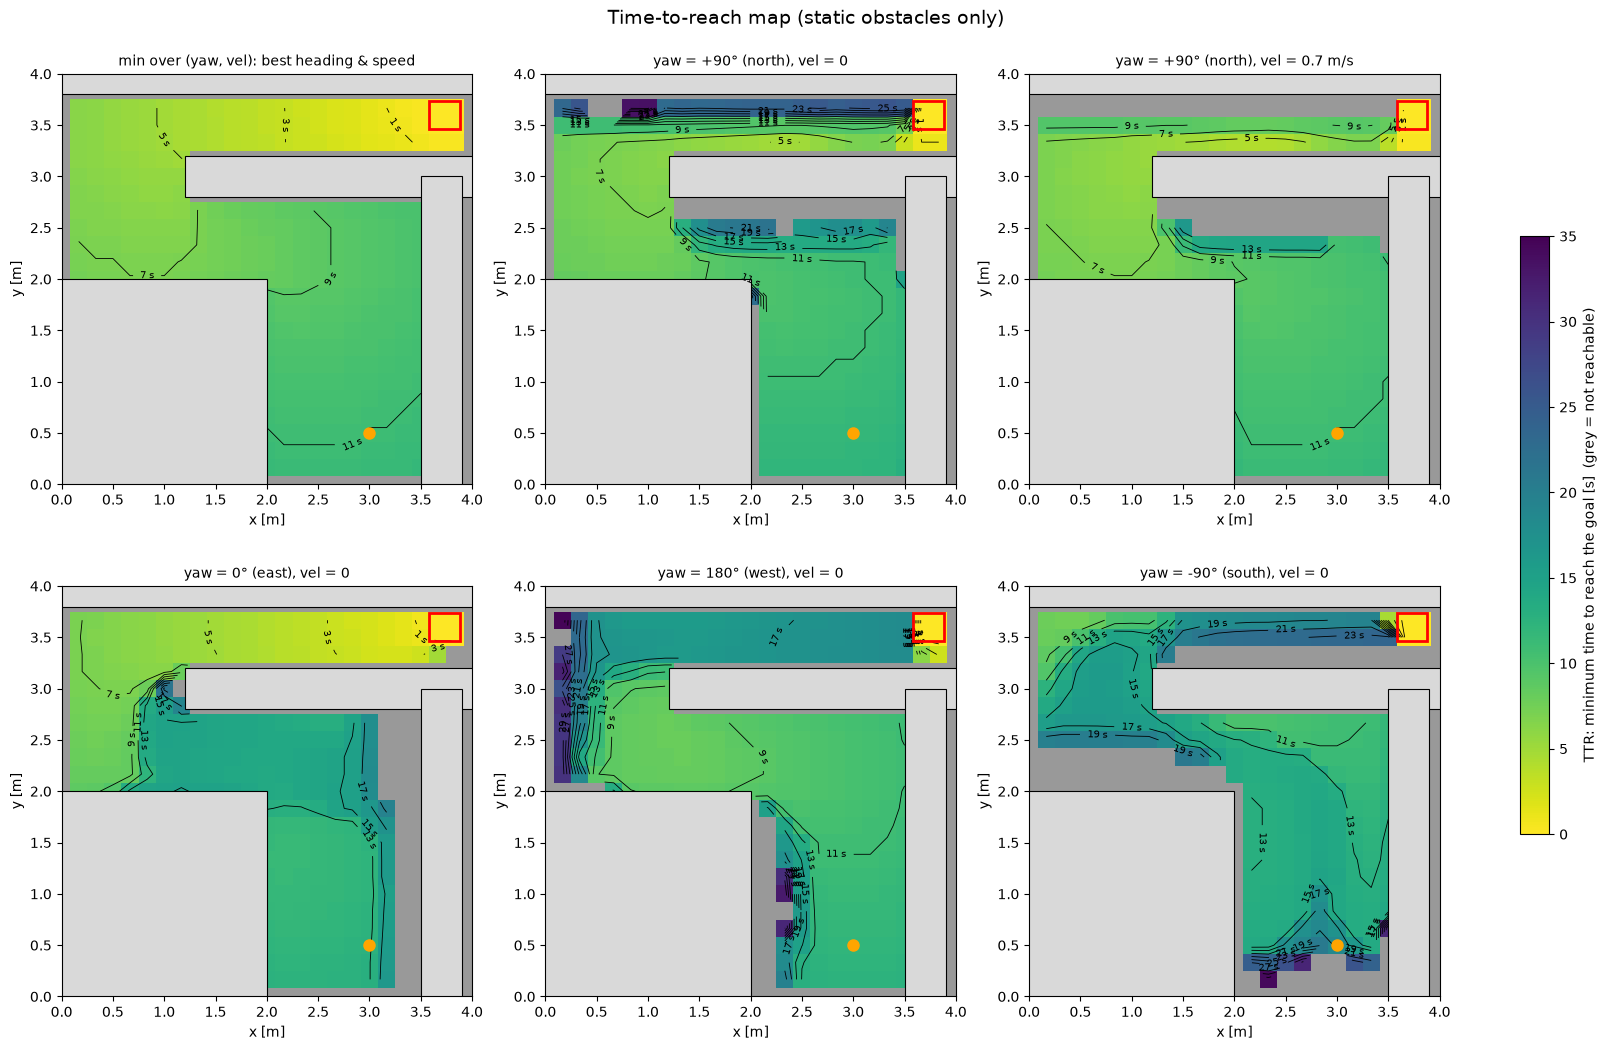

In [ ]:
X_START = [3.0, 0.5, np.pi / 2, 0.0]   # runtime.py initial state

def idx(coords, v):
    return int(np.argmin(np.abs(coords - v)))

def draw_map(ax):
    for (ox, oy, ow, oh) in cfg['obstacles']:
        ax.add_patch(Rectangle((ox, oy), ow, oh, facecolor='0.85', edgecolor='k', lw=0.8, zorder=3))
    gx, gy, gw, gh = cfg['goal']
    ax.add_patch(Rectangle((gx, gy), gw, gh, fill=False, edgecolor='red', lw=2, zorder=4))
    ax.plot(X_START[0], X_START[1], 'o', color='orange', ms=8, zorder=5)
    ax.set_xlim(cfg['X0'], cfg['XW']); ax.set_ylim(cfg['Y0'], cfg['YW'])
    ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')

cmap = plt.get_cmap('viridis_r').copy()
cmap.set_bad('0.6')   # grey = goal not reachable within the horizon

def plot_ttr_xy(ax, Z, title):
    Zm = np.ma.masked_where(Z >= TTR_MAX, Z)
    pc = ax.pcolormesh(x_c, y_c, Zm.T, cmap=cmap, vmin=0, vmax=TTR_MAX, shading='nearest')
    cs = ax.contour(x_c, y_c, Zm.T, levels=np.arange(1, TTR_MAX, 2), colors='k', linewidths=0.6)
    ax.clabel(cs, fmt='%d s', fontsize=7)
    draw_map(ax)
    ax.set_title(title, fontsize=10)
    return pc

iv0, ivmax = 0, len(vel_c) - 1
panels = [
    (ttr.min(axis=(2, 3)),                        "min over (yaw, vel): best heading & speed"),
    (ttr[:, :, idx(yaw_c, np.pi/2), iv0],         "yaw = +90° (north), vel = 0"),
    (ttr[:, :, idx(yaw_c, np.pi/2), ivmax],       f"yaw = +90° (north), vel = {vel_c[ivmax]:.1f} m/s"),
    (ttr[:, :, idx(yaw_c, 0.0), iv0],             "yaw = 0° (east), vel = 0"),
    (ttr[:, :, idx(yaw_c, np.pi), iv0],           "yaw = 180° (west), vel = 0"),
    (ttr[:, :, idx(yaw_c, -np.pi/2), iv0],        "yaw = -90° (south), vel = 0"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10.5), constrained_layout=True)
for ax, (Z, title) in zip(axes.flat, panels):
    pc = plot_ttr_xy(ax, Z, title)
fig.colorbar(pc, ax=axes, shrink=0.6, label='TTR: minimum time to reach the goal [s]  (grey = not reachable)')
fig.suptitle('Time-to-reach map (static obstacles only)', fontsize=14)
plt.show()

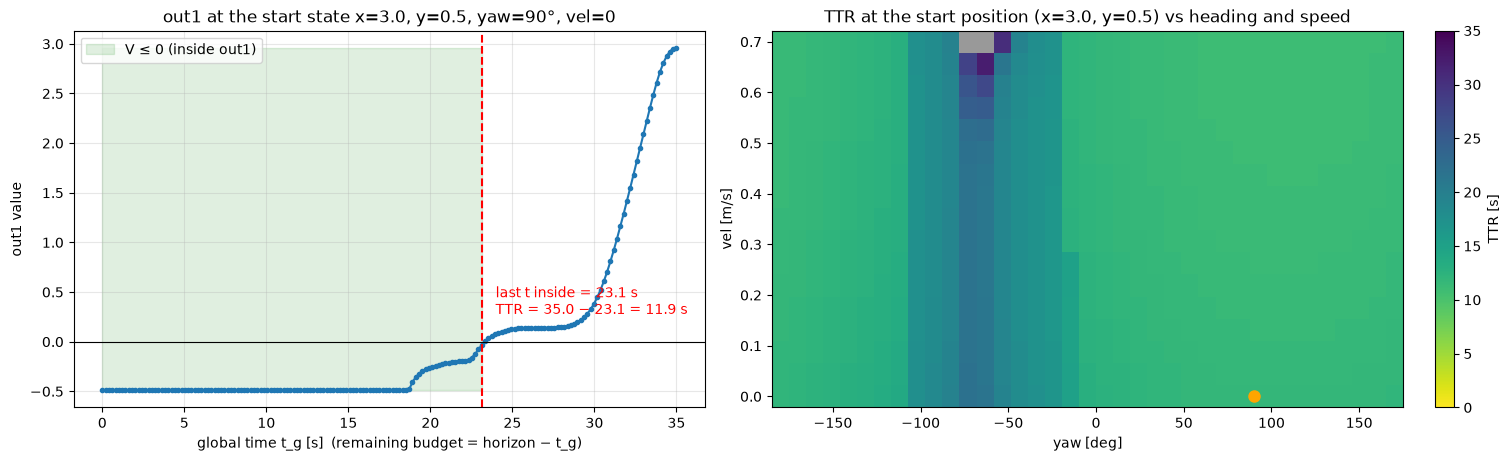

In [ ]:
# How TTR is obtained for one state: the time profile of out1 at the start state
ii = tuple(idx(c, v) for c, v in zip((x_c, y_c, yaw_c, vel_c), X_START))
profile = np.asarray(out1_cfg)[(slice(None), *ii)]
inside = profile <= 0
last = np.where(inside)[0][-1] if inside.any() else None

fig, (axA, axB) = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)

axA.plot(time_grid, profile, '.-', color='tab:blue')
axA.axhline(0, color='k', lw=0.8)
axA.fill_between(time_grid, profile.min(), profile.max(), where=inside, color='green', alpha=0.12, label='V ≤ 0 (inside out1)')
if last is not None:
    t_last = time_grid[last]
    axA.axvline(t_last, color='red', ls='--')
    axA.annotate(f"last t inside = {t_last:.1f} s\nTTR = {time_grid[-1]:.1f} − {t_last:.1f} = {time_grid[-1] - t_last:.1f} s",
                 xy=(t_last, 0), xytext=(10, 20), textcoords='offset points', color='red')
axA.set_xlabel('global time t_g [s]  (remaining budget = horizon − t_g)')
axA.set_ylabel('out1 value')
axA.set_title(f'out1 at the start state x={X_START[0]}, y={X_START[1]}, yaw=90°, vel=0')
axA.legend(loc='upper left'); axA.grid(alpha=0.3)

# TTR at the start position as a function of heading and speed
Z = ttr[ii[0], ii[1]]
Zm = np.ma.masked_where(Z >= TTR_MAX, Z)
pc = axB.pcolormesh(np.degrees(yaw_c), vel_c, Zm.T, cmap=cmap, vmin=0, vmax=TTR_MAX, shading='nearest')
axB.plot(np.degrees(X_START[2]), X_START[3], 'o', color='orange', ms=8)
fig.colorbar(pc, ax=axB, label='TTR [s]')
axB.set_xlabel('yaw [deg]'); axB.set_ylabel('vel [m/s]')
axB.set_title(f'TTR at the start position (x={X_START[0]}, y={X_START[1]}) vs heading and speed')
plt.show()

## Environment

The map the vehicle navigates (from `config.py`), drawn as a small urban scene: the static obstacles are a park with trees (O1) and buildings with rooftop units (O2–O4), the goal is a parking spot and the ego car is shown at its start state. The first figure shows only the static environment. The second figure adds the dynamic obstacle as a tram moving up and down (same model as `obstacles.crossing_events`, used by the verifier and the animation), drawn at time `T_SNAP`; any part of it inside a building is hidden.

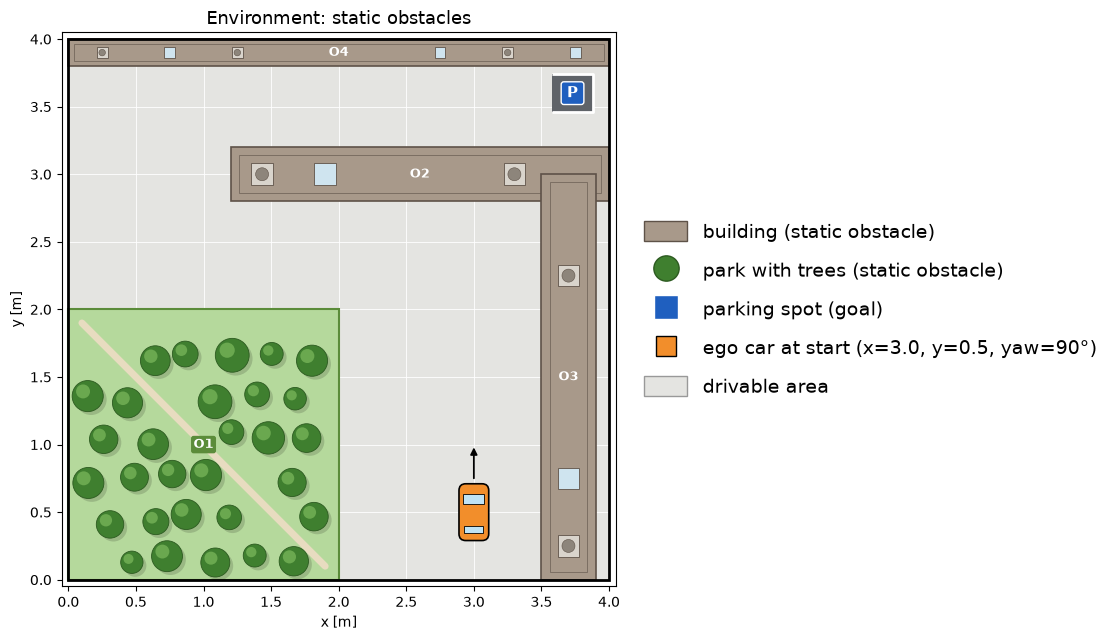

In [ ]:
from matplotlib.patches import Rectangle, FancyBboxPatch, Circle
from matplotlib.lines import Line2D
import matplotlib.transforms as mtransforms
from obstacles import obstacle_rects

X_START = [3.0, 0.5, np.pi / 2, 0.0]   # runtime.py initial state
PARKS = {0}   # indices of cfg['obstacles'] drawn as a park with trees (0 = O1); the others are buildings

# colours
C_ROAD    = '#e4e4e1'   # free space (asphalt, top view)
C_ROOF    = '#a8998a'   # building roof
C_ROOF_E  = '#5e5248'   # building edge
C_LOT     = '#5f6368'   # parking asphalt
C_SIGN    = '#1f5fbf'   # parking sign
C_CAR     = '#f28e2b'
C_GRASS   = '#b5d99c'
C_GRASS_E = '#5b8c3a'
C_TREE    = '#3f7f2f'
C_TREE_HI = '#6aa84f'
C_TRAM    = '#c8102e'

def draw_building(ax, ox, oy, ow, oh, name=None):
    """Top view of a building: roof with an inner parapet line and rooftop units."""
    ax.add_patch(Rectangle((ox, oy), ow, oh, facecolor=C_ROOF, edgecolor=C_ROOF_E, lw=1.2, zorder=3))
    d = min(0.06, 0.2 * min(ow, oh))
    ax.add_patch(Rectangle((ox + d, oy + d), ow - 2 * d, oh - 2 * d, fill=False,
                           edgecolor=C_ROOF_E, lw=0.6, alpha=0.7, zorder=3))
    # rooftop units (AC boxes / skylights) along the long side, away from the label in the middle
    s_u = 0.4 * min(ow, oh)
    long_x = ow >= oh
    n = int((ow if long_x else oh) / 0.45)
    for k in range(n):
        f = (k + 0.5) / n
        if abs(f - 0.5) < 0.12:
            continue
        ux = ox + f * ow - s_u / 2 if long_x else ox + ow / 2 - s_u / 2
        uy = oy + oh / 2 - s_u / 2 if long_x else oy + f * oh - s_u / 2
        # skip units that would fall where this building overlaps another obstacle
        if any(bx - s_u < ux < bx + bw and by - s_u < uy < by + bh
               for (bx, by, bw, bh) in cfg['obstacles'] if (bx, by, bw, bh) != (ox, oy, ow, oh)):
            continue
        sky = k % 2 == 1
        ax.add_patch(Rectangle((ux, uy), s_u, s_u, facecolor='#cfe4ef' if sky else '#d9d4cc',
                               edgecolor=C_ROOF_E, lw=0.6, zorder=3.5))
        if not sky:   # fan of the AC unit
            ax.add_patch(Circle((ux + s_u / 2, uy + s_u / 2), 0.3 * s_u, facecolor='#8d857b',
                                edgecolor=C_ROOF_E, lw=0.4, zorder=3.6))
    if name:
        ax.text(ox + ow / 2, oy + oh / 2, name, ha='center', va='center', color='white',
                fontsize=9, fontweight='bold', zorder=4)

def draw_park(ax, ox, oy, ow, oh, name=None, seed=3):
    """Top view of a fenced park: grass, a footpath and tree crowns (fixed seed, same picture every run)."""
    ax.add_patch(Rectangle((ox, oy), ow, oh, facecolor=C_GRASS, edgecolor=C_GRASS_E, lw=1.5, zorder=3))
    # diagonal footpath
    ax.plot([ox + 0.05 * ow, ox + 0.95 * ow], [oy + 0.95 * oh, oy + 0.05 * oh], color='#e8dcc0',
            lw=5, solid_capstyle='round', zorder=3.1)
    rng = np.random.default_rng(seed)
    r0, step = 0.11, 0.30
    xs_t = np.arange(ox + step / 2, ox + ow - 0.05, step)
    ys_t = np.arange(oy + step / 2, oy + oh - 0.05, step)
    for i, tx in enumerate(xs_t):
        for j, ty in enumerate(ys_t):
            px = tx + rng.uniform(-0.05, 0.05) + (step / 2 if j % 2 else 0)
            py = ty + rng.uniform(-0.05, 0.05)
            r = r0 * rng.uniform(0.75, 1.15)
            if not (ox + r < px < ox + ow - r and oy + r < py < oy + oh - r):
                continue
            # skip trees on the footpath (distance to the diagonal)
            a = np.array([ox + 0.05 * ow, oy + 0.95 * oh]); b = np.array([ox + 0.95 * ow, oy + 0.05 * oh])
            p = np.array([px, py]); u = (b - a) / np.linalg.norm(b - a)
            if abs(u[0] * (p - a)[1] - u[1] * (p - a)[0]) < r * 0.9:
                continue
            ax.add_patch(Circle((px + 0.025, py - 0.025), r, facecolor='k', alpha=0.15, lw=0, zorder=3.2))
            ax.add_patch(Circle((px, py), r, facecolor=C_TREE, edgecolor='#2c5a20', lw=0.6, zorder=3.3))
            ax.add_patch(Circle((px - 0.3 * r, py + 0.3 * r), 0.45 * r, facecolor=C_TREE_HI,
                                lw=0, zorder=3.4))
    if name:
        ax.text(ox + ow / 2, oy + oh / 2, name, ha='center', va='center', color='white',
                fontsize=9, fontweight='bold', zorder=4,
                bbox=dict(boxstyle='round,pad=0.2', fc=C_GRASS_E, ec='none'))

def draw_parking(ax, gx, gy, gw, gh):
    """Parking spot (the goal): asphalt, white stall lines, open on the entry (west) side, P sign."""
    ax.add_patch(Rectangle((gx, gy), gw, gh, facecolor=C_LOT, edgecolor='none', zorder=4))
    lw = 2.0
    ax.plot([gx, gx + gw, gx + gw, gx], [gy, gy, gy + gh, gy + gh], color='white', lw=lw,
            solid_capstyle='butt', zorder=5)
    s = 0.6 * min(gw, gh)
    cx, cy = gx + gw / 2, gy + gh / 2
    ax.add_patch(FancyBboxPatch((cx - s / 2, cy - s / 2), s, s, boxstyle='round,pad=0,rounding_size=0.02',
                                facecolor=C_SIGN, edgecolor='white', lw=1, zorder=6))
    ax.text(cx, cy, 'P', ha='center', va='center', color='white', fontsize=11,
            fontweight='bold', zorder=7)

def draw_car(ax, x, y, yaw, L=0.42, W=0.22):
    """Top view of the ego vehicle at (x, y) with heading yaw."""
    tr = mtransforms.Affine2D().rotate(yaw).translate(x, y) + ax.transData
    ax.add_patch(FancyBboxPatch((-L / 2, -W / 2), L, W, boxstyle='round,pad=0,rounding_size=0.05',
                                facecolor=C_CAR, edgecolor='k', lw=1.2, zorder=8, transform=tr))
    # windscreen (front) and rear window
    ax.add_patch(Rectangle((0.15 * L, -0.35 * W), 0.17 * L, 0.7 * W, facecolor='#bfe3f5',
                           edgecolor='k', lw=0.6, zorder=9, transform=tr))
    ax.add_patch(Rectangle((-0.36 * L, -0.32 * W), 0.11 * L, 0.64 * W, facecolor='#bfe3f5',
                           edgecolor='k', lw=0.6, zorder=9, transform=tr))

def draw_environment(ax, label=True):
    """Map border, buildings (static obstacles), parking spot (goal) and ego car (start)."""
    ax.set_facecolor('white')
    ax.add_patch(Rectangle((cfg['X0'], cfg['Y0']), cfg['XW'] - cfg['X0'], cfg['YW'] - cfg['Y0'],
                           facecolor=C_ROAD, edgecolor='none', zorder=0.1))
    for k, (ox, oy, ow, oh) in enumerate(cfg['obstacles']):
        draw = draw_park if k in PARKS else draw_building
        draw(ax, ox, oy, ow, oh, f'O{k + 1}' if label else None)
    draw_parking(ax, *cfg['goal'])
    xs, ys, yaws = X_START[:3]
    draw_car(ax, xs, ys, yaws)
    ax.annotate('', xy=(xs + 0.5 * np.cos(yaws), ys + 0.5 * np.sin(yaws)),
                xytext=(xs + 0.23 * np.cos(yaws), ys + 0.23 * np.sin(yaws)),
                arrowprops=dict(arrowstyle='-|>', color='k', lw=1.3), zorder=8)
    # map border
    ax.add_patch(Rectangle((cfg['X0'], cfg['Y0']), cfg['XW'] - cfg['X0'], cfg['YW'] - cfg['Y0'],
                           fill=False, edgecolor='k', lw=2, zorder=10))
    ax.set_xlim(cfg['X0'] - 0.05, cfg['XW'] + 0.05)
    ax.set_ylim(cfg['Y0'] - 0.05, cfg['YW'] + 0.05)
    ax.set_aspect('equal')
    ax.set_xticks(np.arange(cfg['X0'], cfg['XW'] + 1e-9, 0.5))
    ax.set_yticks(np.arange(cfg['Y0'], cfg['YW'] + 1e-9, 0.5))
    ax.grid(color='white', lw=0.6, zorder=1)
    ax.set_axisbelow(True)
    ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')

legend_static = [
    Rectangle((0, 0), 1, 1, facecolor=C_ROOF, edgecolor=C_ROOF_E, label='building (static obstacle)'),
    Line2D([], [], marker='o', ls='', ms=13, color=C_TREE, mec='#2c5a20', label='park with trees (static obstacle)'),
    Line2D([], [], marker='s', ls='', ms=12, color=C_SIGN, mec='white', label='parking spot (goal)'),
    Line2D([], [], marker='s', ls='', ms=10, color=C_CAR, mec='k',
           label=f'ego car at start (x={X_START[0]}, y={X_START[1]}, yaw=90°)'),
    Rectangle((0, 0), 1, 1, facecolor=C_ROAD, edgecolor='0.6', label='drivable area'),
]

fig, ax = plt.subplots(figsize=(11, 6.5))
draw_environment(ax)
LEGEND_KW = dict(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=14,
                 markerscale=1.4, handlelength=2.2, handleheight=1.2, labelspacing=0.9)
ax.legend(handles=legend_static, **LEGEND_KW)
ax.set_title('Environment: static obstacles', fontsize=13)
fig.tight_layout()
fig.savefig('environment_static.png', dpi=200, bbox_inches='tight')
plt.show()

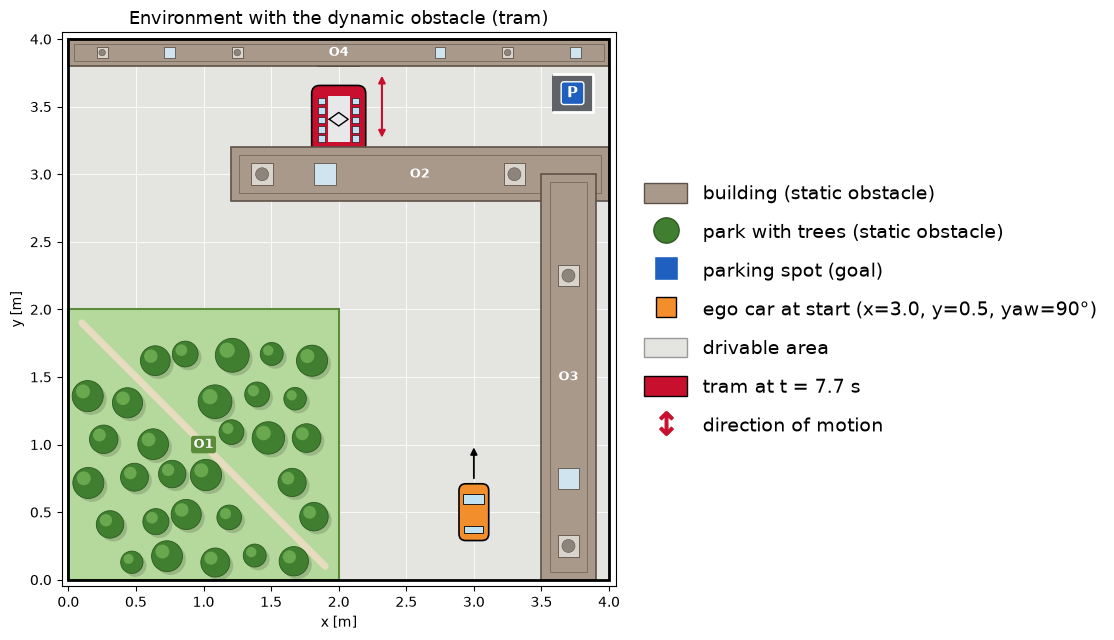

In [ ]:
dyn = cfg['dynamic_obstacle']
y_bot, y_top = dyn['between_y']
xc, w = dyn['center_x'], dyn['width']
# T_SNAP: time at which the tram is drawn [s]. At 7.7 s exactly one tram is in the
# free corridor (crossings overlap in time, see DYN_OBS_CROSSINGS in config.py).
T_SNAP = 7.7

def draw_tram(ax, ox, oy, ow, oh):
    """Top view of a tram occupying the rectangle (ox, oy, ow, oh), clipped to the map."""
    clip = Rectangle((cfg['X0'], cfg['Y0']), cfg['XW'] - cfg['X0'], cfg['YW'] - cfg['Y0'],
                     transform=ax.transData)
    arts = [ax.add_patch(FancyBboxPatch((ox, oy), ow, oh, boxstyle='round,pad=0,rounding_size=0.06',
                                        facecolor=C_TRAM, edgecolor='k', lw=1.2, zorder=2.5))]
    # roof stripe and side windows
    arts.append(ax.add_patch(Rectangle((ox + 0.3 * ow, oy + 0.08), 0.4 * ow, oh - 0.16,
                                       facecolor='#e8e8e8', edgecolor='none', zorder=2.6)))
    for yy in np.arange(oy + 0.08, oy + oh - 0.1, 0.07):
        for xw in (ox + 0.05, ox + ow - 0.10):
            arts.append(ax.add_patch(Rectangle((xw, yy), 0.05, 0.05, facecolor='#bfe3f5',
                                               edgecolor='k', lw=0.4, zorder=2.7)))
    # pantograph
    cx, cy = ox + ow / 2, oy + oh / 2
    arts += ax.plot([cx - 0.07, cx, cx + 0.07, cx, cx - 0.07], [cy, cy + 0.05, cy, cy - 0.05, cy],
                    color='k', lw=1, zorder=2.8)
    for art in arts:
        art.set_clip_path(clip)

fig, ax = plt.subplots(figsize=(11, 6.5))
draw_environment(ax)
# tram at T_SNAP: full body from the obstacle model (not clipped to the band), drawn
# beneath the buildings and clipped to the map
for i, v, y_lo0, y_hi0, t_in, t_out in crossing_events(dyn):
    if t_in <= T_SNAP <= t_out:
        draw_tram(ax, xc - w / 2, y_lo0 + v * (T_SNAP - t_in), w, y_hi0 - y_lo0)
# direction of travel (up and down)
ax.annotate('', xy=(xc + w / 2 + 0.12, y_top - 0.25), xytext=(xc + w / 2 + 0.12, y_bot + 0.25),
            arrowprops=dict(arrowstyle='<|-|>', color=C_TRAM, lw=1.5), zorder=7)
legend_dyn = legend_static + [
    Rectangle((0, 0), 1, 1, facecolor=C_TRAM, edgecolor='k', label=f'tram at t = {T_SNAP:g} s'),
    Line2D([], [], color=C_TRAM, marker='$↕$', ls='', ms=12, label='direction of motion'),
]
ax.legend(handles=legend_dyn, **LEGEND_KW)
ax.set_title('Environment with the dynamic obstacle (tram)', fontsize=13)
fig.tight_layout()
fig.savefig('environment_dynamic.png', dpi=200, bbox_inches='tight')
plt.show()

## Urban road scenario

Top view of the current scenario (`SCENARIO = 'urban_road'` in `config.py`), drawn to scale from the same values the simulation uses: a 120 m two-lane road (3.5 m lanes, 1 m shoulders), sidewalks with trees, lane markings, the three blockages (double-parked van, road works, broken-down car), the goal and the ego car at its start state (4.5 x 1.8 m, rear-axle reference).

The second figure adds the road users crossing the road (same model as `obstacles.crossing_events`): in order along the road, a car at an intersection with a side street, a pedestrian on a zebra crossing, a tram (30 m, much longer than a car) at a tram-line crossing and a second car at another intersection. Each one is drawn halfway through its crossing, with an arrow for its direction. Sidewalks, markings, trees, the side streets and the tram tracks are only drawn: the verifier sees the curbs, the blockages and the crossing rectangles.

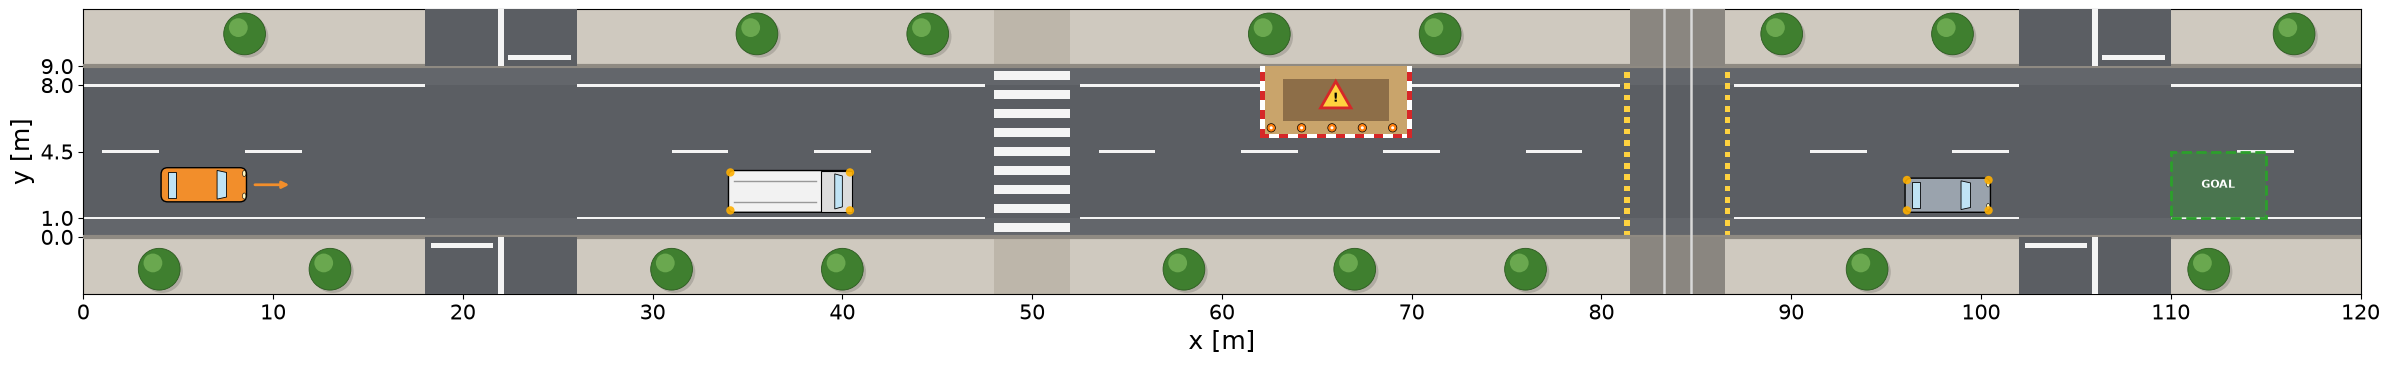

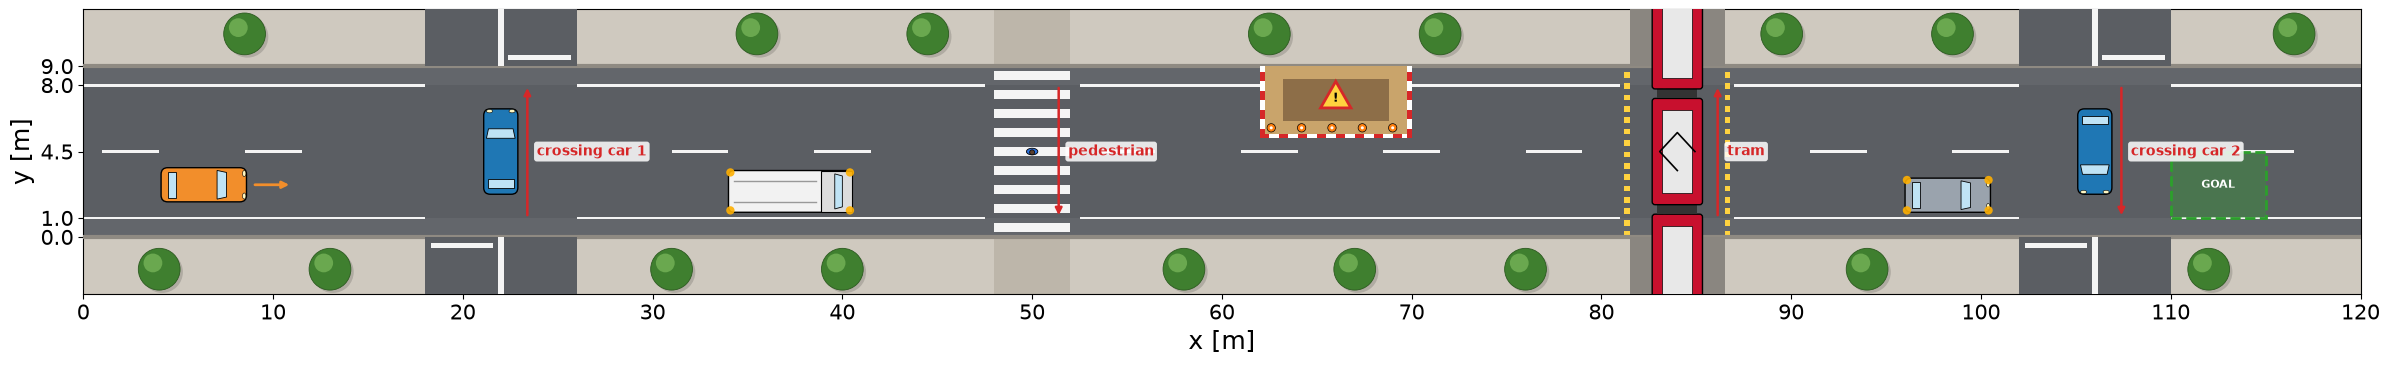

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.patches import Rectangle, FancyBboxPatch, Circle, Ellipse, Polygon
from matplotlib.lines import Line2D

import config
from obstacles import crossing_events

# Configuration of the urban scenario (same values the simulation uses)
_reg = {}
config.run(_reg)
ucfg = _reg['config']
assert ucfg['scenario'] == 'urban_road', "set SCENARIO = 'urban_road' in config.py"

X0, XW, YW = ucfg['X0'], ucfg['X0'] + ucfg['XW'], ucfg['Y0'] + ucfg['YW']
Y_RIGHT, Y_CENTRE, LANE = config.Y_RIGHT, config.Y_CENTRE, config.LANE_WIDTH
VEH = ucfg['vehicle']
STATIC = ucfg['obstacles'][len(config.ROAD_CURBS):]          # blockages (curbs excluded)
DYN = {d['name']: d for d in ucfg['dynamic_obstacles']}
SIDEWALK = 3.0                                               # m, drawn only (not part of the model)

# Where the road users cross: crosswalks for pedestrians, a cycle crossing for
# cyclists, intersections with a side street for crossing cars, a tram line for trams.
CROSSWALKS = [d['center_x'] for d in DYN.values() if d['name'].startswith('pedestrian')]
BIKE_X = [d['center_x'] for d in DYN.values() if d['name'].startswith('cyclist')]
SIDE_STREETS = [d['center_x'] for d in DYN.values() if d['name'].startswith('crossing car')]
TRAM_X = [d['center_x'] for d in DYN.values() if d['name'].startswith('tram')]
CROSSWALK_W, BIKE_W, SIDE_W, TRAM_W = 4.0, 2.0, 8.0, 5.0      # m, extent along x
GAUGE = 1.435                                                 # m, standard track gauge

# colours
C_ASPHALT, C_SHOULDER = '#5b5e63', '#63666b'
C_SIDEWALK, C_CURB = '#cfc9bf', '#8f8a82'
C_MARK = '#f4f4f4'
C_BIKE = '#c0392b'
C_EGO = '#f28e2b'
C_GLASS = '#bfe3f5'
C_HAZARD = '#ffb000'
C_TREE, C_TREE_HI = '#3f7f2f', '#6aa84f'
C_TRAM, C_TRACKBED, C_RAIL = '#c8102e', '#8a8680', '#d9d9d9'


def _body(ax, x, y, yaw, x_b, y_b, length, width, fc, rounding=0.35, z=6, **kw):
    """Rounded rectangle [x_b, x_b + length] x [y_b, y_b + width] in a body frame placed at (x, y, yaw).
    Returns the transform of the body frame."""
    tr = mtransforms.Affine2D().rotate(yaw).translate(x, y) + ax.transData
    ax.add_patch(FancyBboxPatch((x_b, y_b), length, width, boxstyle=f'round,pad=0,rounding_size={rounding}',
                                facecolor=fc, edgecolor='k', lw=1.0, zorder=z, transform=tr, **kw))
    return tr


def draw_car(ax, x, y, yaw, length, width, rear, fc, z=6, hazards=False):
    """Top view of a car; (x, y) = centre of the rear axle, body [-rear, length - rear]."""
    tr = _body(ax, x, y, yaw, -rear, -width / 2, length, width, fc, z=z)
    xf = length - rear
    # windscreen, roof, rear window
    ax.add_patch(Polygon([[xf - 1.55, -0.42 * width], [xf - 1.05, -0.36 * width],
                          [xf - 1.05, 0.36 * width], [xf - 1.55, 0.42 * width]],
                         facecolor=C_GLASS, edgecolor='k', lw=0.6, zorder=z + 0.1, transform=tr))
    ax.add_patch(Rectangle((-rear + 0.35, -0.38 * width), 0.45, 0.76 * width, facecolor=C_GLASS,
                           edgecolor='k', lw=0.6, zorder=z + 0.1, transform=tr))
    # headlights
    for s in (-1, 1):
        ax.add_patch(Ellipse((xf - 0.12, s * 0.33 * width), 0.18, 0.32, facecolor='#fff7c2',
                             edgecolor='k', lw=0.4, zorder=z + 0.1, transform=tr))
    if hazards:
        for cx_ in (-rear + 0.1, xf - 0.1):
            for s in (-1, 1):
                ax.add_patch(Circle((cx_, s * (width / 2 - 0.1)), 0.22, facecolor=C_HAZARD, alpha=0.9,
                                    edgecolor='none', zorder=z + 0.2, transform=tr))


def draw_van(ax, ox, oy, ow, oh):
    """Delivery van filling the rectangle, facing +x, hazard lights on."""
    y_c = oy + oh / 2
    tr = _body(ax, ox, y_c, 0.0, 0.0, -oh / 2, ow, oh, '#f2f2f2', rounding=0.3)
    ax.add_patch(Rectangle((ow - 1.6, -oh / 2), 1.6, oh, facecolor='#dcdcdc', edgecolor='k', lw=0.8,
                           zorder=6.05, transform=tr))                               # cab
    ax.add_patch(Polygon([[ow - 0.9, -0.42 * oh], [ow - 0.5, -0.37 * oh], [ow - 0.5, 0.37 * oh],
                          [ow - 0.9, 0.42 * oh]], facecolor=C_GLASS, edgecolor='k', lw=0.6,
                         zorder=6.1, transform=tr))                                  # windscreen
    for yy in (-0.25 * oh, 0.25 * oh):                                               # roof rails
        ax.plot([0.3, ow - 1.9], [yy, yy], color='0.6', lw=1.0, zorder=6.1, transform=tr)
    for cx_ in (0.1, ow - 0.1):
        for s in (-1, 1):
            ax.add_patch(Circle((cx_, s * (oh / 2 - 0.1)), 0.22, facecolor=C_HAZARD, alpha=0.9,
                                edgecolor='none', zorder=6.2, transform=tr))


def draw_roadworks(ax, ox, oy, ow, oh):
    """Work zone: excavated area, red/white barriers on the traffic sides, cones, sign."""
    ax.add_patch(Rectangle((ox, oy), ow, oh, facecolor='#c9a46b', edgecolor='none', zorder=5))
    ax.add_patch(Rectangle((ox + 1.2, oy + 0.9), ow - 2.4, oh - 1.6, facecolor='#8d6e48',
                           edgecolor='none', zorder=5.05))                            # trench
    # barriers along the open sides (bottom = towards the traffic, left/right ends)
    seg = 0.5
    for k, xx in enumerate(np.arange(ox, ox + ow, seg)):
        ax.add_patch(Rectangle((xx, oy), seg, 0.25, facecolor='#d62728' if k % 2 == 0 else 'white',
                               edgecolor='none', zorder=5.2))
    for x_side in (ox, ox + ow - 0.25):
        for k, yy in enumerate(np.arange(oy, oy + oh, seg)):
            ax.add_patch(Rectangle((x_side, yy), 0.25, min(seg, oy + oh - yy),
                                   facecolor='#d62728' if k % 2 == 0 else 'white', edgecolor='none', zorder=5.2))
    for xx in np.arange(ox + 0.6, ox + ow, 1.6):                                      # cones
        ax.add_patch(Circle((xx, oy + 0.55), 0.22, facecolor='#ff7f0e', edgecolor='k', lw=0.5, zorder=5.3))
        ax.add_patch(Circle((xx, oy + 0.55), 0.08, facecolor='white', edgecolor='none', zorder=5.4))
    # triangular "men at work" sign
    sx, sy = ox + ow / 2, oy + oh / 2 + 0.3
    ax.add_patch(Polygon([[sx - 0.8, sy - 0.6], [sx + 0.8, sy - 0.6], [sx, sy + 0.8]],
                         facecolor='#ffd23f', edgecolor='#d62728', lw=2.0, zorder=5.5))
    ax.text(sx, sy - 0.1, '!', ha='center', va='center', fontsize=9, fontweight='bold', zorder=5.6)


def draw_pedestrian(ax, x, y, v):
    """Pedestrian seen from above (shoulders + head), walking along +-y."""
    ax.add_patch(Ellipse((x, y), 0.6, 0.35, facecolor='#2a6fdb', edgecolor='k', lw=0.6, zorder=8))
    ax.add_patch(Circle((x, y + 0.04 * np.sign(v)), 0.13, facecolor='#5a3e2b', edgecolor='k', lw=0.5, zorder=8.1))


def draw_cyclist(ax, x, y, v, length):
    """Bicycle with rider, travelling along +-y."""
    s = np.sign(v)
    ax.plot([x, x], [y - length / 2, y + length / 2], color='k', lw=2.5, solid_capstyle='round', zorder=8)
    ax.plot([x - 0.3, x + 0.3], [y + s * 0.45 * length / 2] * 2, color='k', lw=2, zorder=8)   # handlebar
    ax.add_patch(Ellipse((x, y), 0.55, 0.35, facecolor='#2ca02c', edgecolor='k', lw=0.6, zorder=8.1))
    ax.add_patch(Circle((x, y + s * 0.15), 0.13, facecolor='#ffd23f', edgecolor='k', lw=0.5, zorder=8.2))


def draw_tram(ax, x, y_c, v, length, width, n_mod=5, z=8):
    """Articulated tram seen from above, centred at (x, y_c), travelling along +-y."""
    yaw = np.pi / 2 if v > 0 else -np.pi / 2          # body frame: +x = direction of travel
    gap = 0.5
    seg = (length - (n_mod - 1) * gap) / n_mod
    for k in range(n_mod):
        xb = -length / 2 + k * (seg + gap)
        tr = _body(ax, x, y_c, yaw, xb, -width / 2, seg, width, C_TRAM,
                   rounding=0.8 if k in (0, n_mod - 1) else 0.15, z=z)
        # roof: light band with the equipment boxes
        ax.add_patch(Rectangle((xb + 0.6, -0.3 * width), seg - 1.2, 0.6 * width, facecolor='#e8e8e8',
                               edgecolor='k', lw=0.5, zorder=z + 0.1, transform=tr))
        if k == n_mod // 2:                           # pantograph on the middle module
            xp = xb + seg / 2
            ax.plot([xp - 1.0, xp, xp + 1.0, xp], [0, 0.35 * width, 0, -0.35 * width],
                    color='k', lw=1.2, zorder=z + 0.2, transform=tr)
        if k < n_mod - 1:                             # bellows between the modules
            ax.add_patch(Rectangle((xb + seg, -0.4 * width), gap, 0.8 * width, facecolor='#333333',
                                   edgecolor='none', zorder=z, transform=tr))
    # windscreens at both ends (bidirectional tram)
    for x_end, s in ((length / 2, -1), (-length / 2, 1)):
        ax.add_patch(Polygon([[x_end + s * 0.15, -0.38 * width], [x_end + s * 0.6, -0.42 * width],
                              [x_end + s * 0.6, 0.42 * width], [x_end + s * 0.15, 0.38 * width]],
                             facecolor=C_GLASS, edgecolor='k', lw=0.6, zorder=z + 0.1, transform=tr))


def draw_tree(ax, x, y, r=1.1):
    ax.add_patch(Circle((x + 0.15, y - 0.15), r, facecolor='k', alpha=0.15, lw=0, zorder=2.2))
    ax.add_patch(Circle((x, y), r, facecolor=C_TREE, edgecolor='#2c5a20', lw=0.6, zorder=2.3))
    ax.add_patch(Circle((x - 0.3 * r, y + 0.3 * r), 0.45 * r, facecolor=C_TREE_HI, lw=0, zorder=2.4))


def _in_any(x, centres, half):
    return any(abs(x - c) < half for c in centres)


def draw_road(ax):
    """Asphalt, shoulders, sidewalks with curbs and trees, lane markings, crossings."""
    ax.set_facecolor('#e9e6df')
    # sidewalks and curbs
    for y_sw, y_curb in ((-SIDEWALK, 0.0), (YW, YW)):
        ax.add_patch(Rectangle((X0, y_sw), XW - X0, SIDEWALK, facecolor=C_SIDEWALK, edgecolor='none', zorder=1))
        ax.plot([X0, XW], [y_curb, y_curb], color=C_CURB, lw=3, zorder=3)
    # side streets (intersection): asphalt across the sidewalks, stop lines
    for cx in SIDE_STREETS:
        for y_sw in (-SIDEWALK, YW):
            ax.add_patch(Rectangle((cx - SIDE_W / 2, y_sw), SIDE_W, SIDEWALK, facecolor=C_ASPHALT,
                                   edgecolor='none', zorder=3.1))
        ax.add_patch(Rectangle((cx - 0.15, -SIDEWALK), 0.3, SIDEWALK, facecolor=C_MARK, zorder=3.2))
        ax.add_patch(Rectangle((cx - 0.15, YW), 0.3, SIDEWALK, facecolor=C_MARK, zorder=3.2))
        for y_stop in (-0.6, YW + 0.3):                                               # stop lines
            half = (cx - SIDE_W / 2 + 0.3, cx - 0.4) if y_stop < 0 else (cx + 0.4, cx + SIDE_W / 2 - 0.3)
            ax.add_patch(Rectangle((half[0], y_stop), half[1] - half[0], 0.3, facecolor=C_MARK, zorder=3.2))
    # tram line: track bed across the sidewalks
    for cx in TRAM_X:
        for y_sw in (-SIDEWALK, YW):
            ax.add_patch(Rectangle((cx - TRAM_W / 2, y_sw), TRAM_W, SIDEWALK, facecolor=C_TRACKBED,
                                   edgecolor='none', zorder=3.1))
    # carriageway and shoulders
    ax.add_patch(Rectangle((X0, 0), XW - X0, YW, facecolor=C_ASPHALT, edgecolor='none', zorder=1.5))
    for y_sh in (0.0, YW - (Y_RIGHT - 0.0)):
        ax.add_patch(Rectangle((X0, y_sh), XW - X0, Y_RIGHT, facecolor=C_SHOULDER, edgecolor='none', zorder=1.6))
    # lane markings: solid edge lines, dashed centre line (3 m dash, 4.5 m gap),
    # interrupted at crossings and at the intersection
    gaps = [(c, CROSSWALK_W / 2 + 0.5) for c in CROSSWALKS] + [(c, BIKE_W / 2 + 0.5) for c in BIKE_X] + \
           [(c, SIDE_W / 2) for c in SIDE_STREETS] + [(c, TRAM_W / 2 + 0.5) for c in TRAM_X]
    def free(x):
        return not any(abs(x - c) < h for c, h in gaps)
    xs = np.arange(X0, XW, 0.25)
    for y_line in (Y_RIGHT, Y_CENTRE + LANE):
        for x in xs:
            if free(x) and free(x + 0.25) and not _in_any(x, SIDE_STREETS, SIDE_W / 2):
                ax.add_patch(Rectangle((x, y_line - 0.075), 0.25, 0.15, facecolor=C_MARK, edgecolor='none', zorder=2))
    for x in np.arange(X0 + 1.0, XW, 7.5):
        if free(x) and free(x + 3.0):
            ax.add_patch(Rectangle((x, Y_CENTRE - 0.075), 3.0, 0.15, facecolor=C_MARK, edgecolor='none', zorder=2))
    # zebra crossings: stripes parallel to the traffic, 0.5 m wide every 1 m
    for cx in CROSSWALKS:
        for y in np.arange(0.25, YW - 0.4, 1.0):
            ax.add_patch(Rectangle((cx - CROSSWALK_W / 2, y), CROSSWALK_W, 0.5, facecolor=C_MARK,
                                   edgecolor='none', zorder=2.1))
        for y_sw in (-SIDEWALK, YW):                                                   # kerb ramps
            ax.add_patch(Rectangle((cx - CROSSWALK_W / 2, y_sw), CROSSWALK_W, SIDEWALK,
                                   facecolor='#bdb6aa', edgecolor='none', zorder=1.1))
    # cycle crossing: red surface and square "elephant feet" markings, cycle path on the sidewalks
    for cx in BIKE_X:
        ax.add_patch(Rectangle((cx - BIKE_W / 2, 0), BIKE_W, YW, facecolor=C_BIKE, alpha=0.55,
                               edgecolor='none', zorder=2.05))
        for y in np.arange(0.1, YW - 0.3, 0.9):
            for xe in (cx - BIKE_W / 2 - 0.25, cx + BIKE_W / 2 - 0.25):
                ax.add_patch(Rectangle((xe, y), 0.5, 0.5, facecolor=C_MARK, edgecolor='none', zorder=2.1))
        for y_sw in (-SIDEWALK, YW):
            ax.add_patch(Rectangle((cx - BIKE_W / 2, y_sw), BIKE_W, SIDEWALK, facecolor=C_BIKE,
                                   alpha=0.55, edgecolor='none', zorder=1.2))
    # tram line: rails across the whole road and the sidewalks, warning lines before it
    for cx in TRAM_X:
        for xr in (cx - GAUGE / 2, cx + GAUGE / 2):
            ax.plot([xr, xr], [-SIDEWALK, YW + SIDEWALK], color=C_RAIL, lw=1.8, zorder=3.3)
        for xw in (cx - TRAM_W / 2 - 0.3, cx + TRAM_W / 2):
            for y in np.arange(0.0, YW, 0.6):
                ax.add_patch(Rectangle((xw, y), 0.3, 0.3, facecolor='#ffd23f', edgecolor='none', zorder=2.1))
    # trees on the sidewalks, away from crossings, side streets and the tram line
    def tree_ok(x):
        return not (_in_any(x, CROSSWALKS + BIKE_X, 4.5) or _in_any(x, SIDE_STREETS, SIDE_W / 2 + 2.0)
                    or _in_any(x, TRAM_X, TRAM_W / 2 + 2.0))
    for x in np.arange(X0 + 4.0, XW - 2.0, 9.0):
        if tree_ok(x):
            draw_tree(ax, x, -SIDEWALK + 1.3)
        if tree_ok(x + 4.5) and x + 4.5 < XW - 2.0:
            draw_tree(ax, x + 4.5, YW + SIDEWALK - 1.3)


def draw_goal(ax, gx, gy, gw, gh):
    ax.add_patch(Rectangle((gx, gy), gw, gh, facecolor='#2ca02c', alpha=0.35, edgecolor='none', zorder=4))
    ax.add_patch(Rectangle((gx, gy), gw, gh, fill=False, edgecolor='#2ca02c', lw=2, ls='--', zorder=4.1))
    ax.text(gx + gw / 2, gy + gh / 2, 'GOAL', ha='center', va='center', color='white', fontsize=8,
            fontweight='bold', zorder=4.2)


def draw_scenario(ax, road_users=True):
    draw_road(ax)
    van, works, broken = STATIC
    draw_van(ax, *van)
    draw_roadworks(ax, *works)
    bx, by, bw, bh = broken
    draw_car(ax, bx + 0.9, by + bh / 2, 0.0, bw, bh, 0.9, '#9aa3ad', z=6, hazards=True)
    draw_goal(ax, *ucfg['goal'])
    xs, ys, yaw = ucfg['x_init'][:3]
    draw_car(ax, xs, ys, yaw, VEH['length'], VEH['width'], VEH['rear_overhang'], C_EGO, z=7)
    ax.annotate('', xy=(xs + 6.0, ys), xytext=(xs + VEH['length'] - VEH['rear_overhang'] + 0.3, ys),
                arrowprops=dict(arrowstyle='-|>', color=C_EGO, lw=2), zorder=7)
    if road_users:
        for d in ucfg['dynamic_obstacles']:
            for i, v, y_lo0, y_hi0, t_in, t_out in crossing_events(d):
                # drawn halfway through its crossing
                t_mid = 0.5 * (t_in + t_out)
                y_mid = 0.5 * (y_lo0 + y_hi0) + v * (t_mid - t_in)
                x = d['center_x']
                if d['name'].startswith('pedestrian'):
                    draw_pedestrian(ax, x, y_mid, v)
                elif d['name'].startswith('cyclist'):
                    draw_cyclist(ax, x, y_mid, v, d['length'])
                elif d['name'].startswith('tram'):
                    draw_tram(ax, x, y_mid, v, d['length'], d['width'])
                else:   # crossing car: body along +-y, (x, y) of draw_car is the rear axle
                    yaw_c = np.pi / 2 if v > 0 else -np.pi / 2
                    draw_car(ax, x, y_mid - np.sign(v) * (d['length'] / 2 - 0.9), yaw_c,
                             d['length'], d['width'], 0.9, '#1f77b4', z=8)
                y0, y1 = (1.0, YW - 1.0) if v > 0 else (YW - 1.0, 1.0)
                # arrow next to the road user (outside the cycle crossing / the tram body)
                if d['name'].startswith('cyclist'):
                    xa = x + BIKE_W / 2 + 0.7
                elif d['name'].startswith('tram'):
                    xa = x + d['width'] / 2 + 0.8
                else:
                    xa = x + 1.4
                ax.annotate('', xy=(xa, y1), xytext=(xa, y0),
                            arrowprops=dict(arrowstyle='-|>', color='#d62728', lw=1.8), zorder=9)
                ax.text(xa + 0.5, YW / 2, f"{d['name']}",
                        ha='left', va='center', fontsize=10, color='#d62728', fontweight='bold', zorder=9,
                        bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.85))
    ax.set_xlim(X0, XW)
    ax.set_ylim(-SIDEWALK, YW + SIDEWALK)
    ax.set_aspect('equal')
    ax.set_xticks(np.arange(X0, XW + 1e-9, 10.0))
    ax.set_yticks([0, Y_RIGHT, Y_CENTRE, Y_CENTRE + LANE, YW])
    ax.set_xlabel('x [m]', fontsize=18); ax.set_ylabel('y [m]', fontsize=18)
    ax.tick_params(axis='both', labelsize=15)


legend_urban = [
    Line2D([], [], marker='s', ls='', ms=11, color=C_EGO, mec='k',
           label=f"ego car (start)"),
    Rectangle((0, 0), 1, 1, facecolor='#f2f2f2', edgecolor='k', label='double-parked van'),
    Rectangle((0, 0), 1, 1, facecolor='#c9a46b', edgecolor='#d62728', label='road works'),
    Rectangle((0, 0), 1, 1, facecolor='#9aa3ad', edgecolor='k', label='broken-down car'),
    Rectangle((0, 0), 1, 1, facecolor='#2ca02c', alpha=0.5, edgecolor='#2ca02c', ls='--', label='goal (stop)'),
    Rectangle((0, 0), 1, 1, facecolor=C_TRAM, edgecolor='k', label='tram (30 m)'),
    Line2D([], [], color='#d62728', marker='$↕$', ls='', ms=12, label='crossing road user'),
]

for road_users, name in ((False, 'environment_urban_static.png'), (True, 'environment_urban_dynamic.png')):
    fig, ax = plt.subplots(figsize=(24, 4.6))
    draw_scenario(ax, road_users=road_users)
    # ax.legend(handles=legend_urban if road_users else legend_urban[:-2], loc='upper center',
            #   bbox_to_anchor=(0.5, -0.28), ncol=7, frameon=False, fontsize=20)
    # ax.set_title('Urban road scenario' + (': road users crossing' if road_users else ''), fontsize=13)
    fig.tight_layout()
    fig.savefig(name, dpi=200, bbox_inches='tight')
    plt.show()

In [ ]:
# Scenario exactly as in the paper figure (plot_snapshots.py, first row): drawn by
# urban_scene.py (blue ego car, orange crossing cars, light asphalt, goal over the lane),
# saved on its own for ONE COLUMN of the paper: clean version, no text inside the map
# (road-user names and the GOAL label would be unreadable at that size).
import importlib
import urban_scene as us
import plot_snapshots as ps
importlib.reload(us); importlib.reload(ps)

WIDTH, PAPER_WIDTH = 12.0, 3.5    # drawing width / column width in the paper (in)
FS_PAPER = 8                      # axis font size in the paper (pt)
FS = FS_PAPER * WIDTH / PAPER_WIDTH

fig, ax = plt.subplots(figsize=(WIDTH, 2.3))
us.draw_scenario(ax, road_users=True)
for txt in list(ax.texts):                 # road-user names and GOAL label
    if txt.get_bbox_patch() is not None or txt.get_text() == 'GOAL':
        txt.remove()
ps.style_axes(ax, FS, show_x=True)
ax.set_xticks(np.arange(us.X0, us.XW + 1e-9, 20.0))   # 20 m: readable in a column
ax.tick_params(axis='both', width=0.08 * FS, length=0.35 * FS, pad=0.2 * FS)
ax.yaxis.labelpad = 0.2 * FS
fig.savefig('results/paper/scenario_urban.pdf', bbox_inches='tight', pad_inches=0.02)
fig.savefig('results/paper/scenario_urban.png', dpi=300, bbox_inches='tight', pad_inches=0.02)
plt.show()